# Trabajo Práctico Integrador - Introducción al Análisis de Datos
## ***Entrega 3*** - Visualización e interpretación de datos 

**Caso:** análisis y predicción de cancelaciones en reservas hoteleras.

> La empresa busca comprender qué factores influyen en la cancelación de reservas en hoteles urbanos y resort, analizando variables como fechas de estadía, tipo de cliente, canal de reserva, historial previo y tarifas, con el fin de identificar patrones y mejorar la gestión operativa.

## Desarrollado por

- **Integrantes:** `Matias Carro`
- **Comisión:** 11
- **Dataset asignado:** Dataset K
- **Entrega:** Primer Entrega - Semana 3
- **Fecha:** 

## Importación de librerías

### Librerias a utilizar:

- **pandas:** para cargar el dataset y trabajar con datos en forma de tablas (DataFrames).
- **numpy:** para realizar operaciones numéricas y manejar arreglos de forma eficiente.
- **matplotlib (pyplot):** para construir la estructura base de gráficos, controlar ejes, etiquetas y personalizar elementos visuales.
- **seaborn:** para generar visualizaciones estadísticas de alto nivel (histogramas, boxplots, gráficos de barras y mapas de correlación) con estilos claros y comparativos.

In [4]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)
print("Versión de Matplotlib:", plt.matplotlib.__version__)
print("Versión de Seaborn:", sns.__version__)
print("Version de DuckDB: ", duckdb.__version__)
print("\nLibrerías cargadas correctamente.")


Versión de Pandas: 3.0.5
Versión de NumPy: 2.5.2
Versión de Matplotlib: 3.11.1
Versión de Seaborn: 0.13.2
Version de DuckDB:  1.5.6

Librerías cargadas correctamente.


## 1. Presentacion del problema

El caso de estudio se centra en el análisis de reservas hoteleras con el objetivo de comprender qué factores están asociados a la cancelación de estadías. El dataset asignado contiene información detallada de cada reserva, incluyendo tipo de hotel, fechas de llegada, duración de la estadía, composición del grupo, país de origen, canal de reserva, tipo de cliente, historial previo, tarifa promedio por noche y características operativas como depósito, agente, pedidos especiales y cambios realizados.


### Relación entre datos, información y conocimiento
En este trabajo partimos de los **datos** que son valores crudos del sistema de reservas: fechas, cantidades, categorías y códigos.  
Mediante el análisis exploratorio estos datos se convierten en **información**, como distribuciones, patrones y diferencias entre reservas canceladas y no canceladas.  
A partir de esa información generamos el **conocimiento** que nos permite entender el comportamiento de los clientes y detectar factores que podrían influir en la cancelación de una reserva.  

Esta relación es clave para el caso: los datos del hotel por sí solos no dicen nada, pero al transformarlos en información y luego interpretarlos, podemos identificar variables relevantes (como `lead_time`, `deposit_type` o `customer_type`) que ayudan a explicar por qué algunas reservas se cancelan y otras no.

### Ciclo de vida del análisis
Este trabajo se enmarca en el ciclo de vida del análisis de datos, que incluye:
1. Obtención del dataset asignado.  
2. Comprensión inicial del problema (cancelaciones hoteleras).  
3. Exploración y limpieza mínima (EDA).  
4. Transformación y preparación de variables relevantes.  
5. Interpretación y comunicación de resultados.

### Variable objetivo
La **variable objetivo** del análisis es **`is_canceled`**, que indica si la reserva fue cancelada (`1`) o no (`0`).  
Su distribución será calculada y analizada en las próximas secciones para comprender el comportamiento general del conjunto de datos y orientar las preguntas del análisis.

### Preguntas iniciales que orientan el trabajo
- ¿Qué características diferencian a las reservas canceladas de las no canceladas?  
- ¿Influyen el tipo de hotel o el canal de reserva en la cancelación?  
- ¿Las reservas con mayor anticipación (`lead_time`) presentan mayor probabilidad de cancelación?  
- ¿Los clientes con pedidos especiales o estacionamiento tienden a cancelar menos?  
- ¿Las políticas de depósito (`deposit_type`) reducen la cancelación?  
- ¿Existen segmentos de mercado con mayor riesgo de cancelación?  


---

## 2. Dataset Asignado

- **Comisión:** 11
- **Dataset asignado:** Dataset K


---

## 3. Carga del dataset

Se carga el Dataset perteneciente a la comisión 11:


In [5]:
df = pd.read_csv("hotel booking TPI grupo K.csv")

print("Dataset cargado correctamente.")

Dataset cargado correctamente.


---

## 4. Resumen del dataset

Resumen de los datos 

In [6]:
filas, columnas = df.shape
print(f"El dataset tiene {filas} filas y {columnas} columnas.")

print("Columnas del dataset:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.info())

El dataset tiene 25000 filas y 32 columnas.
Columnas del dataset:
['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   booking_id                      25000 non-null  str    
 1   hotel                          

El dataset tiene 25.000 filas y 32 columnas.  
Las variables incluyen información temporal, categórica y numérica relevante para el análisis.


### Diccionario de variables 

| Variable | Traducción | Representación | Tipo de Datos |
|----------|------------|----------------|-----------|
| booking_id | ID de reserva | Identificador único de cada reserva. | str |
| hotel | Tipo de hotel | Indica si la reserva corresponde a City Hotel (Ciudad) o Resort Hotel (Resort). | str |
| is_canceled | Cancelada | Indica si la reserva fue cancelada (1) o no (0). | int64 |
| lead_time | Anticipación | Días entre la fecha de reserva y la fecha de llegada. | int64 |
| arrival_date_year | Año de llegada | Año en el que el huésped llega al hotel. | int64 |
| arrival_date_month | Mes de llegada | Mes en el que el huésped llega al hotel. | str |
| arrival_date_week_number | Semana de llegada | Número de semana del año en la que llega el huésped. | int64 |
| arrival_date_day_of_month | Día del mes de llegada | Día del mes en el que llega el huésped. | int64 |
| arrival_date | Fecha de llegada | Fecha completa de llegada (YYYY-MM-DD). | str |
| stays_in_weekend_nights | Noches de fin de semana | Cantidad de noches en fines de semana. | int64 |
| stays_in_week_nights | Noches de semana | Cantidad de noches de lunes a jueves. | int64 |
| adults | Adultos | Número de adultos en la reserva. | int64 |
| children | Niños | Número de niños en la reserva. | float64 |
| babies | Bebés | Número de bebés en la reserva. | int64 |
| meal | Tipo de comida | Plan de comidas asociado a la reserva (BB, HB, SC, etc.). | str |
| country | País | País de origen del huésped. | str |
| market_segment | Segmento de mercado | Tipo de cliente según el canal de adquisición. | str |
| distribution_channel | Canal de distribución | Canal por el cual se realizó la reserva. | str |
| is_repeated_guest | Huésped repetido | Indica si el cliente ya se alojó anteriormente. | int64 |
| previous_cancellations | Cancelaciones previas | Cantidad de reservas previas canceladas por el cliente. | int64 |
| previous_bookings_not_canceled | Reservas previas no canceladas | Cantidad de reservas previas completadas por el cliente. | int64 |
| reserved_room_type | Habitación reservada | Tipo de habitación solicitada originalmente. | str |
| assigned_room_type | Habitación asignada | Tipo de habitación finalmente asignada. | str |
| booking_changes | Cambios en la reserva | Número de modificaciones realizadas a la reserva. | int64 |
| deposit_type | Tipo de depósito | Política de depósito aplicada. | str |
| agent | Agente | Código del agente que gestionó la reserva. | float64 |
| company | Compañía | Código de la empresa asociada a la reserva. | float64 |
| days_in_waiting_list | Días en lista de espera | Tiempo que la reserva permaneció en espera antes de confirmarse. | int64 |
| customer_type | Tipo de cliente | Clasificación del cliente (Transient, Contract, Group, etc.). | str |
| adr | Tarifa promedio diaria | Precio promedio por noche de la reserva. | float64 |
| required_car_parking_spaces | Estacionamiento requerido | Cantidad de espacios de estacionamiento solicitados. | int64 |
| total_of_special_requests | Pedidos especiales | Número de solicitudes especiales realizadas por el cliente. | int64 |




---

# 5. Cambios realizados en Entrega 1 y 2 - Semana 4 y 5 

Limpieza y Transformacion de Datos 

### 0. Preparativos

Se crea una copia del dataset original para conservar un respaldo íntegro de los datos. A partir de este punto, todas las modificaciones se realizarán exclusivamente sobre la copia de trabajo.

El dataset original permanece sin alteraciones y funciona como *referencia histórica* ante cualquier revisión o necesidad de volver al estado inicial.

In [7]:
df_original = df.copy()
print("Copia del dataset creada correctamente.")

Copia del dataset creada correctamente.


### Limpieza 

Se procede a aplicar la limpieza realizada ya en el paso 4:

In [8]:
#Se elimina booking_id
print("\nLimpieza de booking_id\n")

df.drop(columns=['booking_id'], inplace=True)

print("booking_id eliminado correctamente")

# Eliminación de la variable arrival_date_week_number
print("Limpieza de arrival_date_week_number")
df.drop(columns=['arrival_date_week_number'], inplace=True)

print("arrival_date_week_number eliminado correctamente")

# Verificación: mostrar las columnas actuales para confirmar que ya no están
print("Columnas actuales del DataFrame:")
print(df.columns.tolist())

#Limpieza de stays_in_week_nights
print("\nLimpieza de stays_in_week_nights\n")

#los índices de las filas con 0 noches en ambos campos
indices_cero_noches = df[(df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0)].index

# Eliminar esas filas por índice
df= df.drop(index=indices_cero_noches).reset_index(drop=True)

#revision:
print("Revision:")
noches_cero = (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0)

cantidad_cero = noches_cero.sum()
porcentaje = (cantidad_cero / len(df)) * 100

print(f"Cantidad de reservas con 0 noches: {cantidad_cero}")
print("Filas con 0 noches en total eliminadas")

#Limpieza de Adults:
print("\nLimpieza de Adults\n")

#Registros inválidos (sin huéspedes o menores sin adultos)
cero_huespedes = (df['adults'] == 0) & (df['children'].fillna(0) == 0) & (df['babies'] == 0)
menores_solos = (df['adults'] == 0) & ((df['children'] > 0) | (df['babies'] > 0))

indices_a_eliminar = df[cero_huespedes | menores_solos].index

#Eliminar del DataFrame de trabajo
df = df.drop(index=indices_a_eliminar).reset_index(drop=True)
#Verificación
print(f"\nReservas con 0 huéspedes en total restantes: {len(indices_a_eliminar)}")
print("Filas erroneas eliminadas")

#Limpieza de children
print("\nLimpieza de Children\n")

# Convertir a tipo entero 
df['children'] = df['children'].astype(int)

# Verificación del tipo de dato
print(f"Nuevo tipo de dato en children: {df['children'].dtype}")

#Limpieza de babies
print("\nLimpieza de Babies\n")

#Indices de valores imposibles
indices_bebes_imposibles = df[df['babies'] >= 9].index

#Eliminar
df = df.drop(index=indices_bebes_imposibles).reset_index(drop=True)

# 3. Verificación
print(f"Registros eliminados: {len(indices_bebes_imposibles)}")
print(f"Valores resultantes en babies: {sorted(df['babies'].unique().tolist())}")
print("Se elimina correctamente los valores extremadamente altos en babies")

#Limpieza de meal
print("\nLimpieza de Meal\n")

# Unificar 'Undefined' en 'SC' (Self Catering)
df['meal'] = df['meal'].replace('Undefined', 'SC')

# Verificación de categorías resultantes y distribución final
print("Valores únicos en meal:")
print(sorted(df['meal'].unique().tolist()))

print("\nDistribución final de frecuencias:")
print(pd.DataFrame({
    'Cantidad': df['meal'].value_counts(),
    'Porcentaje (%)': (df['meal'].value_counts(normalize=True) * 100).round(2)
}))

#Limpieza de Agent
print("\nLimpieza de Agent\n")

#Reemplazar etiquetas 'Undefined' por 0
df['agent'] = df['agent'].replace('Undefined', 0)
df['agent'] = df['agent'].fillna(0)

#Casteo del tipo de dato de float64 a int64
df['agent'] = df['agent'].astype('int64')

# Verificación
print(f"Valores nulos restantes en agent: {df['agent'].isnull().sum()}")
print(f"Tipo de dato resultante: {df['agent'].dtype}")
print(f"Cantidad de reservas sin agente (código 0): {(df['agent'] == 0).sum()}")

# Frecuencias de los principales códigos
print("\nPrimeras 10 frecuencias de agent:")
display(df['agent'].value_counts().head(10))

#Limpieza de Company
print("\nLimpieza de Company\n")

#Cantidad de nulos

faltantes = df['company'].isnull().sum()
print(f"Nulos en company: {faltantes}")

# nulos con 0 para representar 'Sin Empresa'
df['company'] = df['company'].fillna(0).astype('int64')

# Verificación de la imputación
print("\nSe cambian los nulos como 0")
print("\nNulos restantes en company:", df['company'].isnull().sum())
sin_empresa = (df['company'] == 0).sum()
print(f"Cantidad de reservas sin compañia (0 como valor): {sin_empresa}")

#Limpieza de indices negativos en ADR
print("\nLimpieza de ADR\n")

indices_negativos = df[df['adr'] < 0].index

df = df.drop(index=indices_negativos)

# Verificación
print("Filas con ADR negativo eliminadas")




Limpieza de booking_id

booking_id eliminado correctamente
Limpieza de arrival_date_week_number
arrival_date_week_number eliminado correctamente
Columnas actuales del DataFrame:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Limpieza de stays_in_week_nights

Revision:
Cantidad de reservas con 0 noches: 0
Filas con 0 noches en total eliminadas

Limpieza de Adults


Reservas con 0 huéspedes en total restantes: 63
Filas erroneas eliminadas

Limpieza de Children

Nuevo tipo de dato en c

agent
9      6638
0      3429
240    2869
1      1507
7       770
14      747
6       708
250     560
241     368
28      334
Name: count, dtype: int64


Limpieza de Company

Nulos en company: 23384

Se cambian los nulos como 0

Nulos restantes en company: 0
Cantidad de reservas sin compañia (0 como valor): 23384

Limpieza de ADR

Filas con ADR negativo eliminadas


## Transformacion

Se aplican las transformaciones de la semana 5

In [9]:
print("\nTransformaciones realizadas: \n")

# Creacion de total_guests
print("\nCreacion de total_guests\n")
df['total_guests'] = df['adults'] + df['children'] + df['babies']

print("\nMuestra de nueva variable:")
columnas_huespedes = ['adults', 'children', 'babies', 'total_guests']
print(df[columnas_huespedes].head(10))


# Creación de la variable derivada binaria is_family
print("\nCreacion de is_family\n")
df['is_family'] = ((df['children'] > 0) | (df['babies'] > 0)).astype(int)

print("\nVerificación de columnas relevantes (primeras filas con familias):")
columnas_familia = ['adults', 'children', 'babies', 'total_guests', 'is_family']
print(df[df['is_family'] == 1][columnas_familia].head())


# Creacion de total_stay_nights
print("\nCreacion de total_stay_nights\n")
df['total_stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

print("Primeras 5 filas con la nueva variable:")
columnas_estadia = ['stays_in_weekend_nights', 'stays_in_week_nights', 'total_stay_nights']
print(df[columnas_estadia].head())


# Creacion de estimated_stay_amount
print("\nCreacion de estimated_stay_amount\n")
df['estimated_stay_amount'] = (df['adr'] * df['total_stay_nights']).round(2)

print("Verificación de las primeras filas calculadas:")
columnas_monto = ['adr', 'total_stay_nights', 'estimated_stay_amount', 'is_canceled']
print(df[columnas_monto].head())


# Transformacion de Lead_time
print("\nTransformacion de Lead_time\n")
cortes_dias = [-1, 7, 30, 90, 365, np.inf]
etiquetas_segmento = ['0-7 días', '8-30 días', '31-90 días', '91-365 días', 'Más de 365 días']

df['lead_time_segment'] = pd.cut(df['lead_time'], bins=cortes_dias, labels=etiquetas_segmento)

print("Verificación de las primeras filas calculadas:")
columnas_anticipacion = ['lead_time', 'lead_time_segment', 'is_canceled']
print(df[columnas_anticipacion].head())

print("\nDistribución de reservas por segmento:")
print(df['lead_time_segment'].value_counts(sort=False))

print("\nTasa de cancelación promedio por segmento (porcentaje):")
print((df.groupby('lead_time_segment')['is_canceled'].mean() * 100).round(2))


# Creacion de has_company y has_agent
print("\nCreacion de has_company y has_agent\n")
df['has_agent'] = (df['agent'] != 0).astype('int8')
df['has_company'] = (df['company'] != 0).astype('int8')

print("Verificación de las primeras filas calculadas:")
columnas_intermediarios = ['agent', 'has_agent', 'company', 'has_company']
print(df[columnas_intermediarios].head())

print("\nDistribución de frecuencias - has_agent:")
print(df['has_agent'].value_counts())
print("\nPorcentajes - has_agent:")
print((df['has_agent'].value_counts(normalize=True) * 100).round(2))

print("\nDistribución de frecuencias - has_company:")
print(df['has_company'].value_counts())
print("\nPorcentajes - has_company:")
print((df['has_company'].value_counts(normalize=True) * 100).round(2))

print("\nCancelación por Agente (%):")
print((df.groupby('has_agent')['is_canceled'].mean() * 100).round(2))

print("\nCancelación por Empresa (%):")
print((df.groupby('has_company')['is_canceled'].mean() * 100).round(2))


# Market Segment y Distribution Channel
print("\nTransformacion de Market Segment y Distribution Channel\n")
df['market_segment'] = df['market_segment'].replace(['Complementary', 'Aviation'], 'Other')
df['distribution_channel'] = df['distribution_channel'].replace('GDS', 'Other')

print("Frecuencias consolidadas - market_segment:")
print(df['market_segment'].value_counts())

print("\nFrecuencias consolidadas - distribution_channel:")
print(df['distribution_channel'].value_counts())


# Has booking changes
print("\nCreacion de has_booking_changes\n")
df['has_booking_changes'] = (df['booking_changes'] > 0).astype('int8')

print("Frecuencias de has_booking_changes:")
print(df['has_booking_changes'].value_counts())

print("\nPorcentajes (%):")
print((df['has_booking_changes'].value_counts(normalize=True) * 100).round(2))

print("\nCancelación por has_booking_changes (%):")
print((df.groupby('has_booking_changes')['is_canceled'].mean() * 100).round(2))



Transformaciones realizadas: 


Creacion de total_guests


Muestra de nueva variable:
   adults  children  babies  total_guests
0       1         0       0             1
1       1         0       0             1
2       2         0       0             2
3       2         0       0             2
4       2         0       0             2
5       2         1       0             3
6       2         0       0             2
7       2         0       0             2
8       3         0       0             3
9       2         0       0             2

Creacion de is_family


Verificación de columnas relevantes (primeras filas con familias):
    adults  children  babies  total_guests  is_family
5        2         1       0             3          1
60       2         1       0             3          1
62       2         1       0             3          1
68       2         2       0             4          1
73       2         2       0             4          1

Creacion de total_stay_nights

Pri

## Resumen de los cambios realizados 

Verificacion de los datos:

In [10]:
columnas_nuevas = [
    'has_agent', 'has_company', 'total_stay_nights', 'total_guests',
    'estimated_stay_amount', 'is_family', 'has_booking_changes', 'lead_time_segment'
]

# VALIDACIONES DE INTEGRIDAD GENERAL Y TAMAÑO
registros_eliminados = len(df_original) - len(df)
assert registros_eliminados >= 0, "Error: Las filas finales no pueden superar a las originales"
assert len(df) == len(df_original) - registros_eliminados, "Error: Discrepancia en el conteo de registros eliminados"
assert df[columnas_nuevas].notna().all().all(), "Error: Existen valores nulos en las columnas nuevas"

# VALIDACIONES DE LIMPIEZA (REGLAS DE NEGOCIO Y CONSISTENCIA)

# Validar eliminación de inconsistencias operativas (noches, huéspedes y adultos)
assert (df['total_stay_nights'] > 0).all(), "Error: Quedaron reservas con 0 noches de estadía"
assert (df['total_guests'] > 0).all(), "Error: Quedaron reservas con 0 huéspedes totales"
assert (df['adults'] > 0).all(), "Error: Quedaron reservas sin adultos responsables"

# Validar depuración de outliers imposibles y errores contables
assert (df['adr'] >= 0).all(), "Error: Se detectaron tarifas diarias (ADR) negativas"

# Validar unificación de categorías y tratamiento de nulos
assert 'Undefined' not in df['meal'].values, "Error: La categoría Undefined en meal no fue reemplazada"
assert df['agent'].isnull().sum() == 0 and df['company'].isnull().sum() == 0, "Error: Quedan valores nulos en agent o company"


#VALIDACIONES DE TRANSFORMACIÓN (INDICADORES BINARIOS Y AGRUPACIONES)

# Validar que las variables binarias solo contengan valores {0, 1}
columnas_binarias = ['has_agent', 'has_company', 'is_family', 'has_booking_changes']
for col in columnas_binarias:
    assert set(df[col].unique()).issubset({0, 1}), f"Error: {col} contiene valores distintos de 0 y 1"

# Validar que las categorías minoritarias fueron agrupadas en 'Other'
assert not {'Aviation', 'Complementary'}.intersection(set(df['market_segment'].unique())), "Error: Categorías minoritarias en market_segment no agrupadas"
assert 'GDS' not in df['distribution_channel'].values, "Error: La categoría GDS no fue agrupada en distribution_channel"

# Validar que el importe estimado no sea negativo
assert (df['estimated_stay_amount'] >= 0).all(), "Error: estimated_stay_amount contiene valores negativos"

print("Todas las validaciones pasaron correctamente.")


# 4. SALIDA INFORMATIVA DEL ESTADO FINAL

print('Filas originales:', len(df_original))
print('Registros eliminados durante la limpieza:', registros_eliminados)
print('Filas del dataset preparado:', len(df))
print('Columnas:', len(df.columns))
print('\nColumnas Nuevas (Nuevas variables):')
print(columnas_nuevas)
print('\nVista del dataset preparado:')
display(df.head())

Todas las validaciones pasaron correctamente.
Filas originales: 25000
Registros eliminados durante la limpieza: 213
Filas del dataset preparado: 24787
Columnas: 38

Columnas Nuevas (Nuevas variables):
['has_agent', 'has_company', 'total_stay_nights', 'total_guests', 'estimated_stay_amount', 'is_family', 'has_booking_changes', 'lead_time_segment']

Vista del dataset preparado:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,...,required_car_parking_spaces,total_of_special_requests,total_guests,is_family,total_stay_nights,estimated_stay_amount,lead_time_segment,has_agent,has_company,has_booking_changes
0,Resort Hotel,0,17,2025,February,21,2025-02-21,0,1,1,...,1,1,1,0,1,58.00,8-30 días,0,1,0
1,Resort Hotel,0,6,2023,November,1,2023-11-01,2,1,1,...,0,2,1,0,3,174.00,0-7 días,1,0,1
2,Resort Hotel,0,45,2024,April,8,2024-04-08,0,1,2,...,0,2,2,0,1,65.00,31-90 días,1,0,1
3,City Hotel,0,95,2024,March,17,2024-03-17,2,3,2,...,0,1,2,0,5,369.75,91-365 días,1,0,0
4,City Hotel,1,277,2024,November,7,2024-11-07,1,2,2,...,0,0,2,0,3,300.00,91-365 días,0,0,0


---

# TPI – Semana 9 · Análisis Exploratorio Inicial (SQL + Python)


## 2. Variable objetivo: `is_canceled`

La variable `is_canceled` indica si la reserva fue cancelada.

- **0:** la reserva no fue cancelada  
- **1:** la reserva sí fue cancelada  

Esta variable será el eje del análisis exploratorio inicial.

---

## 3. Estructura del dataset

El dataset contiene aproximadamente 24.900 reservas luego de la limpieza.  
Las columnas incluyen variables numéricas, categóricas y temporales.  
La estructura es consistente con el diccionario original del dataset hotelero.

### Se utiliza DuckDB para inspeccionar la tabla resultante después de la limpieza.

- Primero se crea la conexion

In [11]:
# Crear conexión en memoria
con = duckdb.connect(":memory:")

# Registrar el DataFrame de trabajo (df)
con.register("df", df)

# Crear tabla SQL a partir del DataFrame
con.execute("""
    CREATE OR REPLACE TABLE reservas AS
    SELECT * FROM df
""")

print(f"Entorno preparado: {len(df):,} registros disponibles en la tabla 'reservas'.")

Entorno preparado: 24,787 registros disponibles en la tabla 'reservas'.


#### Tabla resultante:

In [19]:
describe = con.sql("DESCRIBE reservas")

total_filas = con.sql("SELECT COUNT(*) AS total_filas FROM df")

first_10 = con.sql("SELECT * FROM df LIMIT 10")

print(f"Descipcion de la tabla: \n{describe}")
print(f"\nTotal de filas: \n{total_filas}")
print(f"\nPrimeras 10 filas: \n{first_10}")


Descipcion de la tabla: 
┌─────────────────────────────┬───────────────────────────────────────────────────────────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name         │                                  column_type                                  │  null   │   key   │ default │  extra  │
│           varchar           │                                    varchar                                    │ varchar │ varchar │ varchar │ varchar │
├─────────────────────────────┼───────────────────────────────────────────────────────────────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ hotel                       │ VARCHAR                                                                       │ YES     │ NULL    │ NULL    │ NULL    │
│ is_canceled                 │ BIGINT                                                                        │ YES     │ NULL    │ NULL    │ NULL    │
│ lead_time                   │ BIGINT                         

### Interpretación
El dataset contiene 24787 reservas luego de la limpieza.

Las columnas incluyen variables numéricas, categóricas y temporales.

---


## 4. Selección de variables relevantes

Se seleccionan cinco variables clave para el análisis exploratorio inicial:

1. `is_canceled` — variable objetivo  
2. `lead_time` — anticipación de la reserva  
3. `hotel` — tipo de hotel  
4. `total_stay_nights` — duración total de la estadía  
5. `market_segment` — segmento de mercado  

Estas variables permiten observar patrones iniciales sin comparaciones multivariadas.

---

## 5. Distribución inicial de `is_canceled`

La proporción entre reservas canceladas y no canceladas muestra el comportamiento general del dataset.  


In [20]:
con.sql("""
    SELECT 
        is_canceled,
        COUNT(*) AS cantidad,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM df), 2) AS porcentaje
FROM df
GROUP BY is_canceled
ORDER BY is_canceled;
""")

┌─────────────┬──────────┬────────────┐
│ is_canceled │ cantidad │ porcentaje │
│    int64    │  int64   │   double   │
├─────────────┼──────────┼────────────┤
│           0 │    15546 │      62.72 │
│           1 │     9241 │      37.28 │
└─────────────┴──────────┴────────────┘


### Visualizacion:


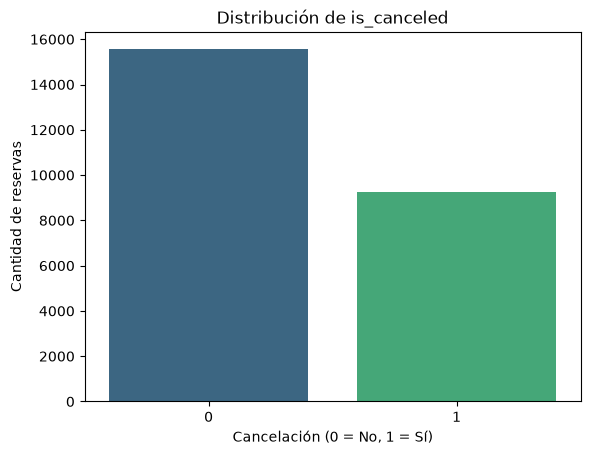

In [22]:

sns.countplot(
    data=df,
    x='is_canceled',
    hue='is_canceled',
    palette='viridis',
    legend=False
)

plt.title('Distribución de is_canceled')
plt.xlabel('Cancelación (0 = No, 1 = Sí)')
plt.ylabel('Cantidad de reservas')
plt.show()


El 62.72% de las reservas no fueron canceladas, mientras que el 37.28% sí se cancelaron. Esto muestra que, aunque la mayoría se completa, la proporción de cancelaciones es considerable dentro del dataset.

---

## 6. Resumen descriptivo de variables seleccionadas y Visualizaciones iniciales

- ### `lead_time` (cuantitativa)

Tabla de frecuencias de la variable


In [28]:
con.sql("""
    SELECT
        COUNT(*) AS cantidad,
        MIN(lead_time) AS minimo,
        MAX(lead_time) AS maximo,
        AVG(lead_time) AS promedio,
        STDDEV(lead_time) AS desviacion
    FROM reservas
""")


┌──────────┬────────┬────────┬────────────────────┬────────────────────┐
│ cantidad │ minimo │ maximo │      promedio      │     desviacion     │
│  int64   │ int64  │ int64  │       double       │       double       │
├──────────┼────────┼────────┼────────────────────┼────────────────────┤
│    24787 │      0 │    629 │ 103.73308589179813 │ 106.66833772600566 │
└──────────┴────────┴────────┴────────────────────┴────────────────────┘

La anticipación de las reservas muestra valores muy bajos y muy altos, indicando que los clientes reservan tanto con pocos días como con muchos meses de anticipación.

### Visualizacion

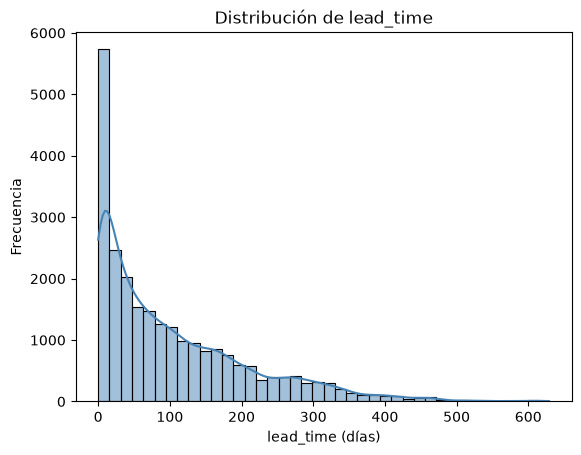

In [29]:
sns.histplot(df['lead_time'], bins=40, kde=True, color='steelblue')
plt.title('Distribución de lead_time')
plt.xlabel('lead_time (días)')
plt.ylabel('Frecuencia')
plt.show()

---

- ### `hotel` (categórica)

Tabla de frecuencias de la variable

In [30]:
con.sql("""
    SELECT 
        hotel,
        COUNT(*) AS cantidad,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reservas), 2) AS porcentaje
    FROM reservas
    GROUP BY hotel
    ORDER BY cantidad DESC
""")


┌──────────────┬──────────┬────────────┐
│    hotel     │ cantidad │ porcentaje │
│   varchar    │  int64   │   double   │
├──────────────┼──────────┼────────────┤
│ City Hotel   │    16583 │       66.9 │
│ Resort Hotel │     8204 │       33.1 │
└──────────────┴──────────┴────────────┘

### Visualizacion:

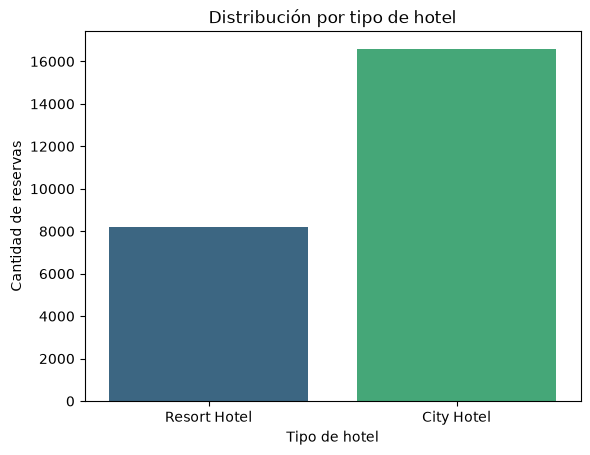

In [33]:
sns.countplot(
    data=df,
    x='hotel',
    hue='hotel',
    palette='viridis',
    legend=False
)

plt.title('Distribución por tipo de hotel')
plt.xlabel('Tipo de hotel')
plt.ylabel('Cantidad de reservas')
plt.show()


El dataset suele tener más reservas en City Hotel que en Resort Hotel.  
Esto puede influir en la proporción de cancelaciones por tipo de hotel.

---

- ### `market_segment` (categórica)

Tabla de frecuencias de la variable



In [34]:
con.sql("""
    SELECT 
        market_segment,
        COUNT(*) AS cantidad,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reservas), 2) AS porcentaje
    FROM reservas
    GROUP BY market_segment
    ORDER BY cantidad DESC
""")


┌────────────────┬──────────┬────────────┐
│ market_segment │ cantidad │ porcentaje │
│    varchar     │  int64   │   double   │
├────────────────┼──────────┼────────────┤
│ Online TA      │    11764 │      47.46 │
│ Offline TA/TO  │     4975 │      20.07 │
│ Groups         │     4152 │      16.75 │
│ Direct         │     2611 │      10.53 │
│ Corporate      │     1100 │       4.44 │
│ Other          │      185 │       0.75 │
└────────────────┴──────────┴────────────┘

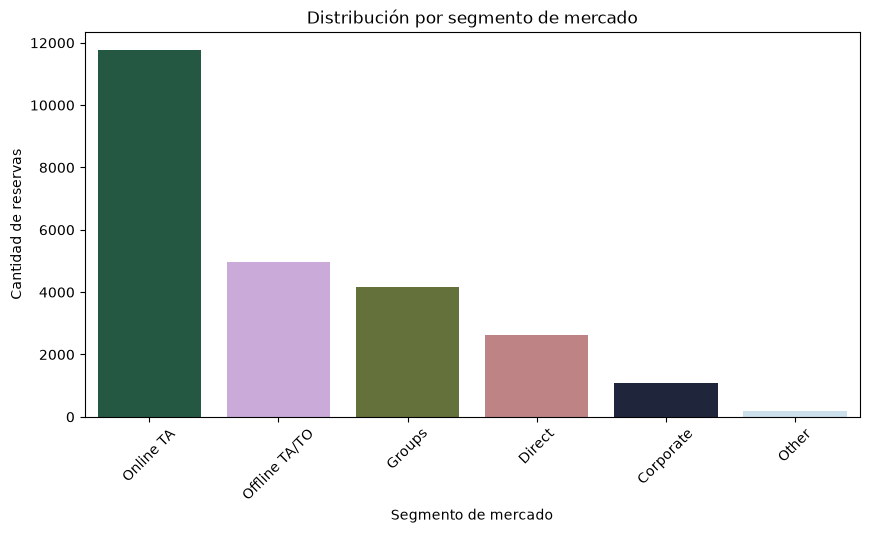

In [ ]:
plt.figure(figsize=(10,5))

# Obtener orden de mayor a menos
orden = df['market_segment'].value_counts().sort_values(ascending=False).index

sns.countplot(
    data=df,
    x='market_segment',
    hue='market_segment',
    palette='cubehelix',
    legend=False,
    order=orden
)

plt.xticks(rotation=45)
plt.title('Distribución por segmento de mercado')
plt.xlabel('Segmento de mercado')
plt.ylabel('Cantidad de reservas')
plt.show()



Los segmentos Online TA y Direct suelen ser los más frecuentes, indicando que la mayoría de las reservas provienen de canales digitales.

---

- ### `total_stay_nights` (cuantitativa)

La mayoría de las estadías son cortas (1–4 noches).  
Las estadías largas son menos frecuentes pero podrían tener comportamientos distintos.

---

In [39]:
con.sql("""
    SELECT
        MIN(total_stay_nights) AS minimo,
        MAX(total_stay_nights) AS maximo,
        AVG(total_stay_nights) AS promedio
    FROM reservas
""")


┌────────┬────────┬────────────────────┐
│ minimo │ maximo │      promedio      │
│ int64  │ int64  │       double       │
├────────┼────────┼────────────────────┤
│      1 │     48 │ 3.4137249364586273 │
└────────┴────────┴────────────────────┘

### Visualizacion
Grafico de densidad (KDE) de `total_stay_nights`

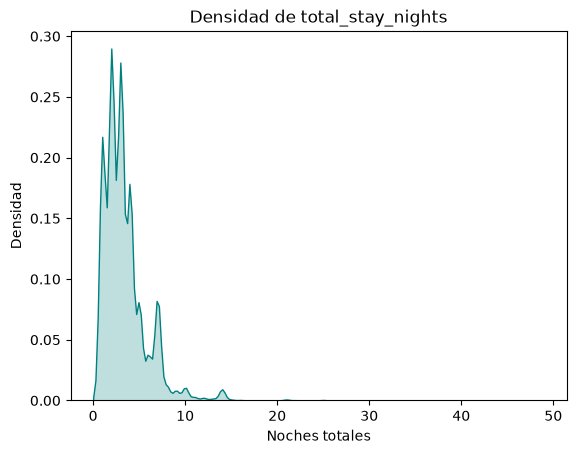

In [41]:
sns.kdeplot(df['total_stay_nights'], fill=True, color='teal')
plt.title('Densidad de total_stay_nights')
plt.xlabel('Noches totales')
plt.ylabel('Densidad')
plt.show()


La distribución está fuertemente concentrada en estadías de pocas noches.

---

## 7. Preguntas e hipótesis para Semana 10

1. ¿La anticipación (`lead_time`) podría estar asociada a la cancelación?  
2. ¿El tipo de hotel muestra diferencias en la proporción de cancelaciones?  
3. ¿El segmento de mercado influye en la probabilidad de cancelar?  
4. ¿La duración de la estadía podría relacionarse con la cancelación?  
5. ¿Existen meses o períodos del año con más cancelaciones?

---

# 8. Cierre

En esta semana se realizó:

- identificación de la unidad de análisis,  
- revisión de la variable objetivo,  
- inspección estructural,  
- selección de variables relevantes,  
- análisis descriptivo inicial,  
- visualizaciones individuales,  
- interpretaciones descriptivas,  
- formulación de hipótesis para la próxima semana.

El dataset está listo para avanzar hacia comparaciones y análisis multivariados en la Semana 10.